In [ ]:
# Project 4: Predict BAC Stock Price Using Machine Learning
# 1) Build ML models to predict BAC's next day price using historical stock data 
# 2) Perform feature engineering
# 3) Apply different ML algorithms such as Decision Tree, Random Forest,K Nearest Neighbors (KNN),Support Vector Regression Prediction models
# 4) Evaluate the model based on R square, rmse, mse, mae and other metri

In [ ]:
# pip install yfinance

In [3]:
# Import all the packages
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px
import yfinance as yf

In [1]:
# 'BAC' => Bank of America Corp (peer finance stock)
# 'JPM' => JP Morgan Chase & Co. (peer finance stock)
# 'MS' => Morgan Stanley (peer finance stock)
# 'C' => Citi Group (peer finance stock)
# 'WFC' => Wells Fargo & Co (peer finance stock)
# 'SPY' => S&P500 ETF (Market Index)
# '^VIX' => CBOE Volatility Index (market fear indicator)
# '^TNX' => 10Y US Treasury Yield (Interest Rate Indicator)
# 'DX-Y.NYB' => US Dollar Index (Strength of US Dollar)
# 'CL=F' => # Crude Oil Future (Inflation/energy proxy)
# 'GC=F' => Gold Futures (safe asset)

In [4]:
# Download the data from yahoo finance
tickers = ['BAC','JPM', 'MS', 'C', 'WFC', 'SPY', '^VIX', '^TNX', 'DX-Y.NYB', 'CL=F', 'GC=F']
data = yf.download(tickers, start = '2002-01-01', end = '2025-01-01')['Close']
data


[*********************100%***********************]  11 of 11 completed


Ticker,BAC,C,CL=F,DX-Y.NYB,GC=F,JPM,MS,SPY,WFC,^TNX,^VIX
Date,,,,,,,,,,,
2002-01-02,17.361128,268.668793,21.010000,115.790001,278.899994,18.150768,27.145842,74.089233,11.001009,5.157,22.709999
2002-01-03,17.341824,268.879486,20.370001,116.110001,278.200012,18.635115,27.932381,74.929413,11.041530,5.120,21.340000
2002-01-04,17.612068,273.883026,21.620001,116.330002,278.899994,19.474010,29.318680,75.429558,11.069379,5.141,20.450001
2002-01-07,17.402496,270.670288,21.480000,116.330002,278.600006,19.424084,29.097464,74.897308,11.087108,5.057,21.940001
2002-01-08,17.123985,260.715576,21.250000,116.830002,278.899994,19.274277,28.487885,74.724167,11.044060,5.057,21.830000
...,...,...,...,...,...,...,...,...,...,...,...
2024-12-24,42.908619,68.055588,70.099998,108.260002,2620.000000,233.964600,121.595062,591.179138,68.932617,4.591,14.270000
2024-12-26,43.072979,68.391068,69.620003,108.129997,2638.800049,234.766022,122.523331,591.218445,69.096321,4.579,14.730000
2024-12-27,42.869942,68.055588,70.599998,108.000000,2617.199951,232.863876,121.307968,584.994995,68.470436,4.619,15.950000


In [6]:
# Statistical Summary of Data
data.describe()

Ticker,BAC,C,CL=F,DX-Y.NYB,GC=F,JPM,MS,SPY,WFC,^TNX,^VIX
count,5789.000000,5789.000000,5779.000000,5807.000000,5775.000000,5789.000000,5789.000000,5789.000000,5789.000000,5783.000000,5789.000000
mean,21.498239,107.089294,66.811741,90.834782,1212.050857,59.286668,36.435610,187.162659,28.755554,3.079020,19.471192
std,9.771054,107.529094,24.071656,10.092435,555.276716,48.261768,23.146223,131.884338,12.657366,1.158701,8.613284
min,2.404095,7.455829,-37.630001,71.330002,278.100006,8.013109,6.273821,49.680557,5.240189,0.499000,9.140000
25%,12.391879,35.666828,48.520000,81.879997,732.649994,24.429138,20.961826,85.842575,17.714584,2.130000,13.610000
50%,22.245342,49.381283,66.230003,90.779999,1253.000000,36.991879,28.461660,131.960419,23.732473,2.979000,17.100000
75%,28.751974,191.776550,84.514999,97.825001,1648.750000,87.869331,41.258263,254.554962,39.886044,4.099500,22.530001
max,45.930729,372.837036,145.289993,120.239998,2788.500000,241.669754,129.184006,595.575012,74.478806,5.428000,82.690002


In [7]:
# How many missing values are present in my dataset
data.isnull().sum()

Ticker
BAC         21
C           21
CL=F        31
DX-Y.NYB     3
GC=F        35
JPM         21
MS          21
SPY         21
WFC         21
^TNX        27
^VIX        21
dtype: int64

In [8]:
# Appplying forward fill on my dataset
data = data.ffill()
data.head()

Ticker,BAC,C,CL=F,DX-Y.NYB,GC=F,JPM,MS,SPY,WFC,^TNX,^VIX
Date,,,,,,,,,,,
2002-01-02,17.361128,268.668793,21.010000,115.790001,278.899994,18.150768,27.145842,74.089233,11.001009,5.157,22.709999
2002-01-03,17.341824,268.879486,20.370001,116.110001,278.200012,18.635115,27.932381,74.929413,11.041530,5.120,21.340000
2002-01-04,17.612068,273.883026,21.620001,116.330002,278.899994,19.474010,29.318680,75.429558,11.069379,5.141,20.450001
2002-01-07,17.402496,270.670288,21.480000,116.330002,278.600006,19.424084,29.097464,74.897308,11.087108,5.057,21.940001
2002-01-08,17.123985,260.715576,21.250000,116.830002,278.899994,19.274277,28.487885,74.724167,11.044060,5.057,21.830000


In [9]:
# How many missing values are present in my dataset
data.isnull().sum()


Ticker
BAC         0
C           0
CL=F        0
DX-Y.NYB    0
GC=F        0
JPM         0
MS          0
SPY         0
WFC         0
^TNX        0
^VIX        0
dtype: int64

In [10]:
# Correlation in our data
data.corr()


Ticker,BAC,C,CL=F,DX-Y.NYB,GC=F,JPM,MS,SPY,WFC,^TNX,^VIX
Ticker,,,,,,,,,,,
BAC,1.000000,0.461779,-0.070637,0.360871,0.071502,0.569557,0.786216,0.544844,0.342323,0.381009,-0.214983
C,0.461779,1.000000,-0.328865,-0.056293,-0.753355,-0.404546,-0.078854,-0.429433,-0.509659,0.716295,-0.165584
CL=F,-0.070637,-0.328865,1.000000,-0.513374,0.436498,0.117551,0.110137,0.140270,0.149889,-0.045080,-0.111997
DX-Y.NYB,0.360871,-0.056293,-0.513374,1.000000,0.165210,0.527508,0.509171,0.542913,0.449883,0.055238,0.003703
GC=F,0.071502,-0.753355,0.436498,0.165210,1.000000,0.787185,0.581200,0.810607,0.694652,-0.526051,-0.022830
JPM,0.569557,-0.404546,0.117551,0.527508,0.787185,1.000000,0.902370,0.987253,0.834764,-0.196493,-0.136455
MS,0.786216,-0.078854,0.110137,0.509171,0.581200,0.902370,1.000000,0.901737,0.660625,0.098139,-0.153446
SPY,0.544844,-0.429433,0.140270,0.542913,0.810607,0.987253,0.901737,1.000000,0.824806,-0.243903,-0.126401
WFC,0.342323,-0.509659,0.149889,0.449883,0.694652,0.834764,0.660625,0.824806,1.000000,-0.322967,-0.333026


In [11]:
# Feature Engineering
df = pd.DataFrame(index = data.index)
# Create lag features - Stock Data
df['JPM(t-1)'] = data['JPM'].shift(1)
df['BAC(t-1)'] = data['BAC'].shift(1)
df['MS(t-1)'] = data['MS'].shift(1)
df['C(t-1)'] = data['C'].shift(1)
df['WFC(t-1)'] = data['WFC'].shift(1)
df['SPY(t-1)'] = data['SPY'].shift(1)
# Create lag features - Macroeconmic Data
df['VIX(t-1)'] = data['^VIX'].shift(1)
df['10Y_Yield(t-1)'] = data['^TNX'].shift(1)
df['Gold_Futures(t-1)'] = data['GC=F'].shift(1)
df['US_Dollar_Index(t-1)'] = data['DX-Y.NYB'].shift(1)
df['Crude_Oil_Futures(t-1)'] = data['CL=F'].shift(1)
# Technical Indicators = Moving Average and Rolling Volatility
df['BAC_MA5'] = data['BAC'].rolling(window = 5).mean().shift(1)
df['BAC_MA10'] = data['BAC'].rolling(window = 10).mean().shift(1)
df['BAC_Volatility5'] = data['BAC'].pct_change(5).shift(1)
# Create Target Variable
df['Target'] = data['BAC']
# Drop nan values
df = df.dropna()
df


,JPM(t-1),BAC(t-1),MS(t-1),C(t-1),WFC(t-1),SPY(t-1),VIX(t-1),10Y_Yield(t-1),Gold_Futures(t-1),US_Dollar_Index(t-1),Crude_Oil_Futures(t-1),BAC_MA5,BAC_MA10,BAC_Volatility5,Target
Date,,,,,,,,,,,,,,,
2002-01-16,18.909760,16.944752,28.552050,261.874512,11.477110,73.845589,22.700001,4.831,284.399994,117.290001,18.900000,16.932066,17.150183,-0.010467,16.765518
2002-01-17,18.230663,16.765518,27.574810,257.344757,11.484707,72.351318,23.450001,4.839,287.299988,117.589996,18.860001,16.868645,17.090622,-0.018563,16.853748
2002-01-18,18.400438,16.853748,28.448395,262.822449,11.550551,72.896431,22.250000,4.933,284.399994,117.849998,18.040001,16.820112,17.041815,-0.014194,16.765518
2002-01-21,17.931065,16.765518,27.944973,263.138397,11.492307,72.562981,22.520000,4.888,283.100006,117.510002,18.000000,16.814598,16.957160,-0.001642,16.765518
2002-01-22,17.931065,16.765518,27.944973,263.138397,11.492307,72.562981,22.520000,4.888,283.100006,117.660004,18.000000,16.819011,16.893462,0.001318,17.281160
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2024-12-24,230.179596,42.434864,119.097305,66.876595,67.921600,584.680359,16.780001,4.599,2612.300049,108.040001,69.239998,42.539284,43.415246,-0.034748,42.908619
2024-12-26,233.964600,42.908619,121.595062,68.055588,68.932617,591.179138,14.270000,4.591,2620.000000,108.260002,70.099998,42.409727,43.282788,-0.014872,43.072979
2024-12-27,234.766022,43.072979,122.523331,68.391068,69.096321,591.218445,14.730000,4.579,2638.800049,108.129997,69.620003,42.612763,43.134860,0.024138,42.869942


In [12]:
# Train our ML Algo
# a) Tell what is X variables and my Y Variable - Supervised ML Algo
# b) Split our data into training and testing (90:10)
# c) Apply ML Algo
# d) Do Prediction
# e) Evaluate the model based on R2, rmse and mse
# f) Visualtion => Actual vs Forecasted

In [13]:
# a) Tell what is X variables and my Y Variable
X = df.drop('Target', axis = 1)
Y = df['Target']

In [ ]:
# b) Split our data into training and testing (90:10)
from sklearn.model_selection import train_test_split
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, shuffle = False, test_size = 0.1)

In [15]:
# c) Apply ML Algo: Decision Tree
from sklearn.tree import DecisionTreeRegressor
dt_model = DecisionTreeRegressor(max_depth = 4) # Calling the DT Model
dt_model.fit(X_train, Y_train) # Train my DT Model
from sklearn.ensemble import RandomForestRegressor
rf_model = RandomForestRegressor(n_estimators = 100)
rf_model.fit(X_train, Y_train)
from sklearn.neighbors import KNeighborsRegressor
knn_model = KNeighborsRegressor(n_neighbors = 5)
knn_model.fit(X_train, Y_train)
from sklearn.svm import SVR
svr_model = SVR()
svr_model.fit(X_train, Y_train)


,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm.If none is given, 'rbf' will be used. If a callable is given it isused to precompute the kernel matrix.For an intuitive visualization of different kernel typessee :ref:`sphx_glr_auto_examples_svm_plot_svm_regression.py`",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive.The penalty is a squared l2. For an intuitive visualization of theeffects of scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"epsilon epsilon: float, default=0.1Epsilon in the epsilon-SVR model. It specifies the epsilon-tubewithin which no penalty is associated in the training loss functionwith points predicted within a distance epsilon from the actualvalue. Must be non-negative.",0.1
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False
,"max_iter max_iter: int, default=-1Hard limit on iterations within solver, or -1 for no limit.",-1


In [16]:
# d) Do Prediction: X_test and Y_test are my actual values
dt_pred = dt_model.predict(X_test)
rf_pred = rf_model.predict(X_test)
knn_pred = knn_model.predict(X_test)
svr_pred = svr_model.predict(X_test)


In [17]:
# Actual vs Predicted = Decision Tree
result = pd.DataFrame(Y_test.index)
result['Actual'] = Y_test.values
result['DT Prediction'] = dt_pred
result['RF Prediction'] = rf_pred
result['KNN Prediction'] = knn_pred
result['SVR Prediction'] = svr_pred
result


,Date,Actual,DT Prediction,RF Prediction,KNN Prediction,SVR Prediction
0,2022-09-12,32.062809,31.423134,31.538459,30.826825,32.383493
1,2022-09-13,30.908291,31.423134,31.788154,30.584963,32.685785
2,2022-09-14,30.790112,31.423134,30.927575,30.630121,31.367415
3,2022-09-15,31.371918,31.423134,30.692580,30.622801,31.490647
4,2022-09-16,31.017376,31.423134,31.300013,30.438959,31.438932
...,...,...,...,...,...,...
575,2024-12-24,42.908619,42.026345,42.003532,33.365675,34.121802
576,2024-12-26,43.072979,42.026345,42.128239,33.365675,34.233490
577,2024-12-27,42.869942,42.026345,42.787595,33.365675,33.853969
578,2024-12-30,42.454201,42.026345,42.076455,33.365675,34.109718


In [18]:
# e) Evaluate the model based on R2, rmse and mse
from sklearn.metrics import r2_score, mean_squared_error
def evaluate_model(y_true, y_pred, model_name):
 r2 = r2_score(y_true, y_pred)
 mse = mean_squared_error(y_true, y_pred) # mse: mean squared error
 rmse = np.sqrt(mse) # rmse: root means sqaured error
 print("Model Name:", model_name)
 print("R2 Value", r2)
 print("MSE", mse)
 print("RMSE", rmse)
 print("\n")

# Y_test = Actual Value
# dt_pred, rf_pred = Predicted Value
evaluate_model(Y_test, dt_pred, "Decision Tree")
evaluate_model(Y_test, rf_pred, "Random Forest")
evaluate_model(Y_test, knn_pred, "K Nearest Neighbor")
evaluate_model(Y_test, svr_pred, "Support Vector Regressor")


Model Name: Decision Tree
R2 Value 0.9582605607301715
MSE 1.2674000021340557
RMSE 1.1257886134324044


Model Name: Random Forest
R2 Value 0.984053103257188
MSE 0.4842206153085807
RMSE 0.6958596232779861


Model Name: K Nearest Neighbor
R2 Value -0.6226696228217767
MSE 49.27166055423723
RMSE 7.01937750475334


Model Name: Support Vector Regressor
R2 Value 0.006117083448186844
MSE 30.178824454628245
RMSE 5.493525685261537




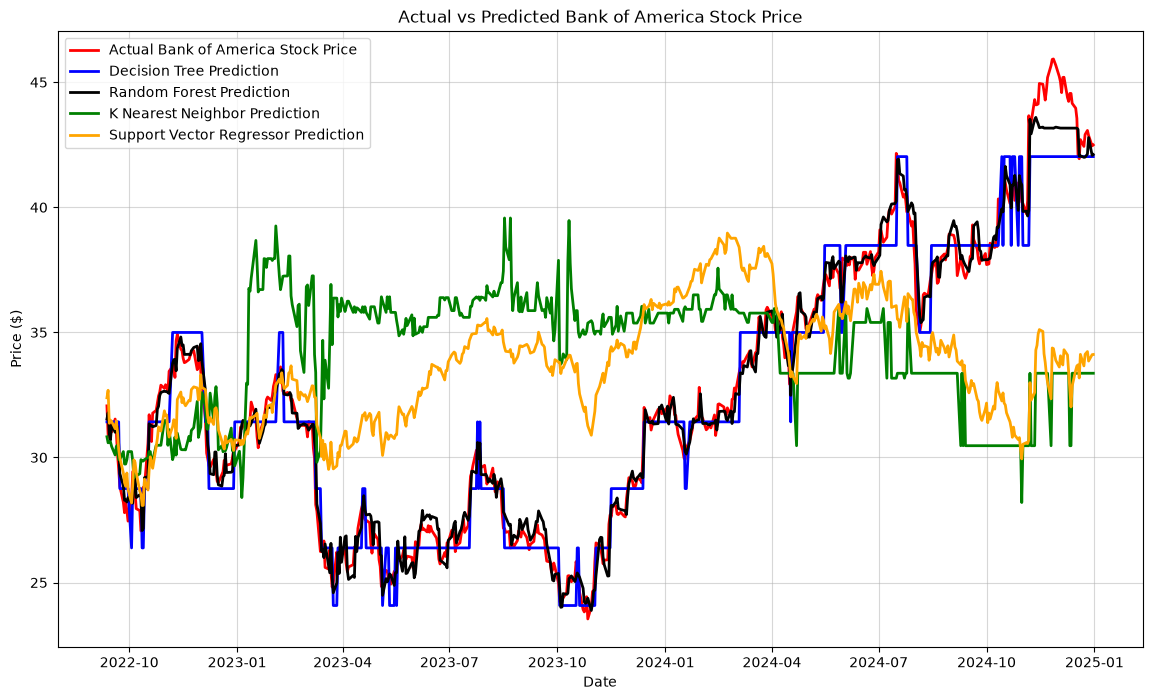

In [19]:
# f) Visualtion => Actual vs Forecasted
# Plot figure => tell figure size
plt.figure(figsize = (14,8))
#Plot Actual Value and Predicted Value (X = Date, Y = Stock Price)
plt.plot(Y_test.index, Y_test, label = 'Actual Bank of America Stock Price',linewidth = 2, color = 'red')
plt.plot(Y_test.index, dt_pred, label = 'Decision Tree Prediction', linewidth = 2, color = 'blue')
plt.plot(Y_test.index, rf_pred, label = "Random Forest Prediction", linewidth = 2, color = 'black')
plt.plot(Y_test.index, knn_pred, label = "K Nearest Neighbor Prediction", linewidth = 2, color = 'green')
plt.plot(Y_test.index, svr_pred, label = "Support Vector Regressor Prediction", linewidth = 2, color = 'orange')
# Highlight title, xlabel, and ylabel
plt.title("Actual vs Predicted Bank of America Stock Price")
plt.xlabel('Date')
plt.ylabel('Price ($)')
plt.grid(alpha = 0.5)
plt.legend()
plt.show()